# Tile 109 2D-3D Label Transfer Validation Gallery

This notebook focuses on image-based validation for tile 109. It follows the overlay style used in the clipping notebooks and combines spatial alignment checks with structural plausibility checks from Z-normalised LiDAR.

The main outputs are:
- An eight-panel gallery with the 2D mask, multispectral tile, LAS-only view, raster-plus-LAS overlay, projected labels, refined labels, and paired 3D views.
- A class-wise height plot to verify that refined labels respect expected vertical structure.

## Refinement Workflow Summary

This summary uses the recorded tile 109 pipeline output from the site 01 workflow notebook.

**Tile 109 inputs**

| Step | Operation | Tile 109 result |
| --- | --- | --- |
| 1 | Compute class-specific height thresholds | Matched 331,887/331,887 structure points to Z_norm; Forb used default 0.0-0.4 m; Woody debris 0.00-0.56 m; Hummock 0.00-0.06 m; Shrub 0.02-0.15 m; Mallee 0.13-1.51 m; mallee crown minimum height 0.60 m. |
| 2 | Cartesian voxel merge | 109,924 voxels with non-zero structure class; labels transferred to 371,048/1,593,979 Z_norm points (23.3%). |
| 3 | Detect mallee crowns | Auto parameters: min_tree_dist = 0.80 m, smoothing_sigma = 1.33 px; watershed identified 56 crowns. |
| 4 | Compute crown IDs from watershed | 332,957 points fall within 56 crowns. |
| 5 | Polar refinement around crowns | Statistics built for 18,241 polar bins; 8,840/1,593,979 labels updated (0.6%). |
| 6 | Final height sanity rules | Rule-based height cleanup applied using the class-specific height ranges. |
| 7 | Filter class-0 and promote high points | Kept 394,473/1,593,979 points (24.7%). |
| 8 | Spatial majority voting within crowns | No additional reclassification lines were reported for tile 109 in the saved pipeline log. |
| 9 | Finalize treeIDs | Assigned 54 unique treeIDs to mallee crowns. |
| 10 | Write output LAS | Wrote znorm_3Dlabels_109.las with 394,473 labelled points across 54 trees. |

> The step-card figure in the next cell presents the same workflow as a compact visual sequence for tile 109.

,Step,Operation,Tile 109 result
0,1,Compute class-specific height thresholds,"Matched 331,887/331,887 structure points; Forb..."
1,2,Cartesian voxel merge,"109,924 labelled voxels; 371,048/1,593,979 Z_n..."
2,3,Detect mallee crowns,"Auto params: min_tree_dist=0.80 m, smoothing_s..."
3,4,Compute crown IDs from watershed,"332,957 points fall within 56 crowns."
4,5,Polar refinement around crowns,"18,241 polar bins built; 8,840/1,593,979 label..."
5,6,Final height sanity rules,Rule-based height cleanup applied using tile-s...
6,7,Filter class-0 and promote high points,"394,473/1,593,979 points kept (24.7%)."
7,8,Spatial majority voting within crowns,No extra within-crown reclassification lines i...
8,9,Finalize treeIDs,54 unique mallee treeIDs assigned.
9,10,Write output LAS,"znorm_3Dlabels_109.las written with 394,473 la..."


🌳 [Watershed] Identified 56 crowns (structure).
Watershed crowns computed: 56 crowns


/tmp/ipykernel_3815422/2259878911.py:250: UserWarning: You passed a edgecolor/edgecolors ('k') for an unfilled marker ('x').  Matplotlib is ignoring the edgecolor in favor of the facecolor.  This behavior may change in the future.
  image_ax.scatter(


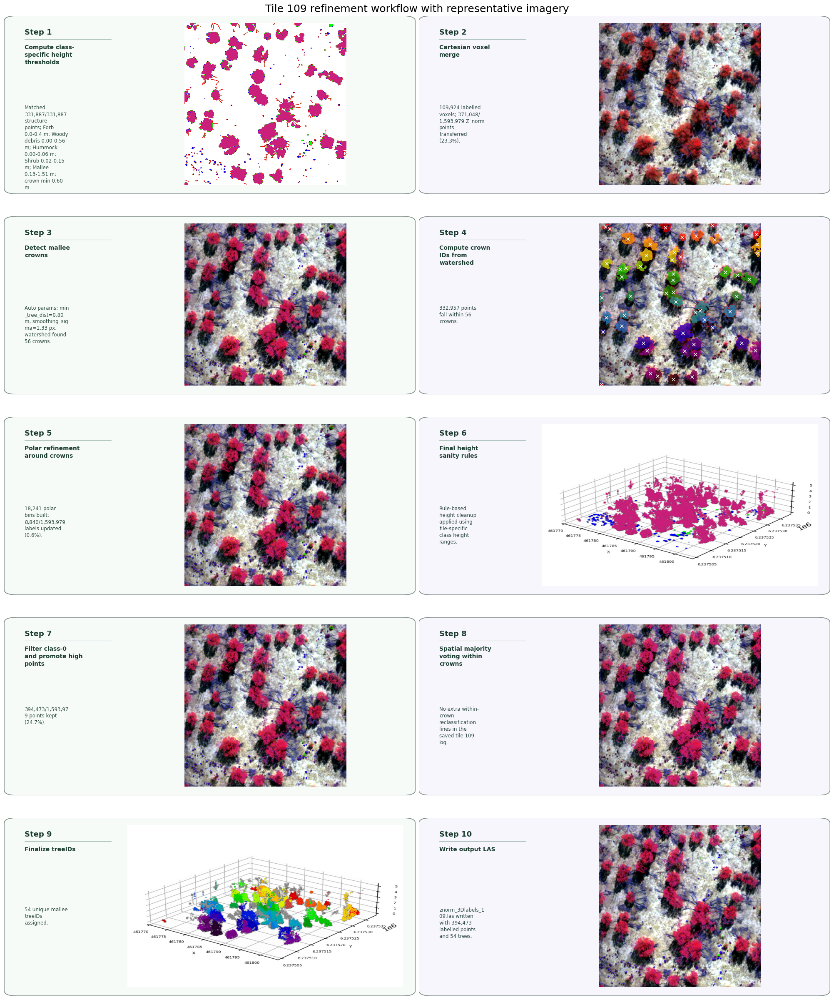

In [56]:
import io
from textwrap import fill

import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
import numpy as np
import pandas as pd


required_names = [
    'rgb_overlay',
    'overlay_extent',
    'projected_las_display',
    'projected_validation',
    'refined_validation',
    'validation_mask_idx',
    'validation_extent',
    'validation_cmap',
    'validation_norm',
    'validation_colors',
    'validation_z',
    'laspy',
    'projected_las_path',
    'tile_id',
]
missing = [name for name in required_names if name not in globals()]
if missing:
    raise RuntimeError(
        'Run Cell 4 and Cell 5 first so the tile 109 imagery and point-cloud variables are available '
        f'for this workflow storyboard. Missing: {missing}'
    )


tile_109_workflow = [
    {
        'Step': '1',
        'Operation': 'Compute class-specific height thresholds',
        'Tile 109 result': 'Matched 331,887/331,887 structure points; Forb 0.0-0.4 m; Woody debris 0.00-0.56 m; Hummock 0.00-0.06 m; Shrub 0.02-0.15 m; Mallee 0.13-1.51 m; crown min 0.60 m.',
    },
    {
        'Step': '2',
        'Operation': 'Cartesian voxel merge',
        'Tile 109 result': '109,924 labelled voxels; 371,048/1,593,979 Z_norm points transferred (23.3%).',
    },
    {
        'Step': '3',
        'Operation': 'Detect mallee crowns',
        'Tile 109 result': 'Auto params: min_tree_dist=0.80 m, smoothing_sigma=1.33 px; watershed found 56 crowns.',
    },
    {
        'Step': '4',
        'Operation': 'Compute crown IDs from watershed',
        'Tile 109 result': '332,957 points fall within 56 crowns.',
    },
    {
        'Step': '5',
        'Operation': 'Polar refinement around crowns',
        'Tile 109 result': '18,241 polar bins built; 8,840/1,593,979 labels updated (0.6%).',
    },
    {
        'Step': '6',
        'Operation': 'Final height sanity rules',
        'Tile 109 result': 'Rule-based height cleanup applied using tile-specific class height ranges.',
    },
    {
        'Step': '7',
        'Operation': 'Filter class-0 and promote high points',
        'Tile 109 result': '394,473/1,593,979 points kept (24.7%).',
    },
    {
        'Step': '8',
        'Operation': 'Spatial majority voting within crowns',
        'Tile 109 result': 'No extra within-crown reclassification lines in the saved tile 109 log.',
    },
    {
        'Step': '9',
        'Operation': 'Finalize treeIDs',
        'Tile 109 result': '54 unique mallee treeIDs assigned.',
    },
    {
        'Step': '10',
        'Operation': 'Write output LAS',
        'Tile 109 result': 'znorm_3Dlabels_109.las written with 394,473 labelled points and 54 trees.',
    },
]

workflow_table = pd.DataFrame(tile_109_workflow)
display(workflow_table)

rng = np.random.default_rng(42)


def sample_indices(length, max_points):
    if length <= max_points:
        return np.arange(length)
    return np.sort(rng.choice(length, size=max_points, replace=False))


def sampled_points(points, max_points):
    keep = sample_indices(len(points['x']), max_points)
    sampled = {}
    for key, value in points.items():
        if value is None:
            sampled[key] = None
        else:
            array = np.asarray(value)
            sampled[key] = array[keep]
    return sampled


sampled_projected = sampled_points(projected_validation, 45_000)
sampled_refined = sampled_points(refined_validation, 45_000)
keep_las = sample_indices(len(projected_las_display['x']), 45_000)
sampled_las_display = {
    'x': np.asarray(projected_las_display['x'])[keep_las],
    'y': np.asarray(projected_las_display['y'])[keep_las],
    'colors': np.asarray(projected_las_display['colors'])[keep_las],
    'use_rgb': bool(projected_las_display['use_rgb']),
}


# image_ax occupies the RIGHT 68% of each card, nearly full height
_IMG_LEFT   = 0.30
_IMG_BOTTOM = 0.05
_IMG_WIDTH  = 0.67
_IMG_HEIGHT = 0.91
# text lives in the LEFT strip
_TEXT_X     = 0.05
_TEXT_WRAP  = 16


def style_image_axis(image_ax, extent):
    image_ax.set_xlim(extent[0], extent[1])
    image_ax.set_ylim(extent[2], extent[3])
    image_ax.set_aspect('equal')
    image_ax.set_xticks([])
    image_ax.set_yticks([])
    for spine in image_ax.spines.values():
        spine.set_visible(False)


def style_flat_axis(image_ax):
    image_ax.set_xticks([])
    image_ax.set_yticks([])
    for spine in image_ax.spines.values():
        spine.set_visible(False)


projected_classes = np.asarray(sampled_projected['class'])
refined_classes = np.asarray(sampled_refined['class'])
refined_z_values = validation_z(sampled_refined)
projected_z_values = validation_z(sampled_projected)
mallee_mask = refined_classes == 68

# --- Watershed crown map for Steps 4 and 9 ---
_watershed_available = False
_ws_labels = _ws_centroids = _ws_min_x = _ws_min_y = None
_ws_extent = overlay_extent
try:
    from fvc3dstruct.watershed import get_mallee_centroids_watershed
    _las_s_ws = laspy.read(str(projected_las_path))
    _clipped_root = projected_las_path.parent.parent.parent.parent
    _znorm_las_path = (
        _clipped_root / 'raster' / 'z_norm' / 'csf'
        / f'z_norm_csf_tiles_multispectral.{tile_id}.las'
    )
    _fallback = None
    if _znorm_las_path.exists():
        _las_z_ws = laspy.read(str(_znorm_las_path))
        try:
            _zn_ws = np.asarray(_las_z_ws.z_norm)
        except AttributeError:
            _zn_ws = np.asarray(_las_z_ws.z, dtype=np.float64) - float(np.percentile(_las_z_ws.z, 1))
        _fallback = (_las_z_ws.x, _las_z_ws.y, _zn_ws)
    if _fallback is not None:
        _ws_labels, _ws_centroids, _ws_min_x, _ws_min_y = get_mallee_centroids_watershed(
            _las_s_ws,
            grid_res=0.10,
            min_tree_dist=0.80,
            smoothing_sigma=1.33,
            fallback_points=_fallback,
            fallback_min_height=1.0,
        )
    else:
        _ws_labels, _ws_centroids, _ws_min_x, _ws_min_y = get_mallee_centroids_watershed(
            _las_s_ws,
            grid_res=0.10,
            min_tree_dist=0.80,
            smoothing_sigma=1.33,
        )
    _ws_extent = (
        float(_ws_min_x),
        float(_ws_min_x) + _ws_labels.shape[1] * 0.10,
        float(_ws_min_y),
        float(_ws_min_y) + _ws_labels.shape[0] * 0.10,
    )
    _watershed_available = True
    print(f'Watershed crowns computed: {int(_ws_labels.max())} crowns')
except Exception as _ws_err:
    print(f'Watershed computation skipped: {_ws_err}')


def plot_mask(image_ax):
    image_ax.imshow(
        validation_mask_idx,
        cmap=validation_cmap,
        norm=validation_norm,
        extent=validation_extent,
        origin='upper',
    )


def plot_lidar_overlay(image_ax):
    image_ax.imshow(rgb_overlay, extent=overlay_extent, origin='upper')
    image_ax.scatter(
        sampled_las_display['x'],
        sampled_las_display['y'],
        s=0.25,
        c=sampled_las_display['colors'],
        alpha=0.5,
        linewidths=0,
    )


def plot_projected_labels(image_ax):
    image_ax.imshow(rgb_overlay, extent=overlay_extent, origin='upper')
    image_ax.scatter(
        sampled_projected['x'],
        sampled_projected['y'],
        s=0.35,
        c=validation_colors(projected_classes),
        alpha=0.7,
        linewidths=0,
    )


def plot_watershed_crowns(image_ax):
    image_ax.imshow(rgb_overlay, extent=overlay_extent, origin='upper')
    if not _watershed_available:
        image_ax.text(
            0.5, 0.5, 'Watershed\nunavailable',
            ha='center', va='center',
            transform=image_ax.transAxes,
            fontsize=8, color='#345548',
        )
        return
    mask_grid = np.ma.masked_where(_ws_labels == 0, _ws_labels)
    image_ax.imshow(mask_grid, origin='lower', cmap='nipy_spectral', extent=_ws_extent, alpha=0.65)
    if _ws_centroids is not None and len(_ws_centroids) > 1:
        image_ax.scatter(
            _ws_centroids[1:, 0],
            _ws_centroids[1:, 1],
            c='white',
            edgecolors='k',
            marker='x',
            s=30,
            linewidths=1.0,
            zorder=5,
        )


def plot_refined_labels(image_ax):
    image_ax.imshow(rgb_overlay, extent=overlay_extent, origin='upper')
    image_ax.scatter(
        sampled_refined['x'],
        sampled_refined['y'],
        s=0.35,
        c=validation_colors(refined_classes),
        alpha=0.72,
        linewidths=0,
    )


def _render_3d_to_image_ax(fig3d, image_ax):
    buf = io.BytesIO()
    fig3d.savefig(buf, format='png', dpi=120, bbox_inches='tight', facecolor='white')
    plt.close(fig3d)
    buf.seek(0)
    image_ax.imshow(plt.imread(buf), aspect='auto')
    style_flat_axis(image_ax)


def plot_refined_height_3d(image_ax):
    x_span = max(overlay_extent[1] - overlay_extent[0], 1e-6)
    y_span = max(overlay_extent[3] - overlay_extent[2], 1e-6)
    z_finite = refined_z_values[np.isfinite(refined_z_values)]
    z_span = max(float(z_finite.max()) - float(z_finite.min()), 1.0)

    z_order = np.argsort(refined_z_values)
    x_s = sampled_refined['x'][z_order]
    y_s = sampled_refined['y'][z_order]
    z_s = refined_z_values[z_order]
    c_s = validation_colors(refined_classes[z_order])

    fig3d = plt.figure(figsize=(4.5, 4.0))
    ax3d = fig3d.add_subplot(111, projection='3d')
    # eyedome lighting simulation: wide dark halo first, coloured points on top
    ax3d.scatter(x_s, y_s, z_s, s=5.0, c='k', alpha=0.10, linewidths=0, depthshade=False)
    ax3d.scatter(x_s, y_s, z_s, s=1.4, c=c_s, alpha=0.88, linewidths=0, depthshade=True)
    ax3d.view_init(elev=28, azim=-52)
    ax3d.set_xlabel('X', fontsize=6, labelpad=1)
    ax3d.set_ylabel('Y', fontsize=6, labelpad=1)
    ax3d.set_zlabel('Z_norm (m)', fontsize=6, labelpad=1)
    ax3d.tick_params(labelsize=5)
    ax3d.set_box_aspect((x_span, y_span, z_span * 2.0))
    ax3d.xaxis.set_major_formatter(plt.matplotlib.ticker.ScalarFormatter(useOffset=False))
    ax3d.yaxis.set_major_formatter(plt.matplotlib.ticker.ScalarFormatter(useOffset=False))
    ax3d.xaxis.pane.set_alpha(0.04)
    ax3d.yaxis.pane.set_alpha(0.04)
    ax3d.zaxis.pane.set_alpha(0.08)
    ax3d.grid(True, alpha=0.18)
    fig3d.tight_layout(pad=0.3)
    _render_3d_to_image_ax(fig3d, image_ax)


def plot_majority(image_ax):
    image_ax.imshow(rgb_overlay, extent=overlay_extent, origin='upper')
    image_ax.scatter(
        sampled_refined['x'],
        sampled_refined['y'],
        s=0.25,
        c=validation_colors(refined_classes),
        alpha=0.2,
        linewidths=0,
    )
    image_ax.scatter(
        sampled_refined['x'][mallee_mask],
        sampled_refined['y'][mallee_mask],
        s=0.45,
        c=validation_colors(refined_classes[mallee_mask]),
        alpha=0.82,
        linewidths=0,
    )


def plot_mallee_only(image_ax):
    image_ax.imshow(rgb_overlay, extent=overlay_extent, origin='upper')
    image_ax.scatter(
        sampled_refined['x'][mallee_mask],
        sampled_refined['y'][mallee_mask],
        s=0.5,
        c=validation_colors(refined_classes[mallee_mask]),
        alpha=0.88,
        linewidths=0,
    )


def plot_mallee_3d_crowns(image_ax):
    """Step 9: mallee-only points in 3D coloured per watershed crown (nipy_spectral),
    with an eyedome-lighting simulation via a dark halo pass."""
    x_m = sampled_refined['x'][mallee_mask]
    y_m = sampled_refined['y'][mallee_mask]
    z_m = refined_z_values[mallee_mask]

    # colour by watershed crown ID (like Step 4)
    if _watershed_available and _ws_labels is not None:
        col_idx = np.floor((x_m - _ws_min_x) / 0.10).astype(int)
        row_idx = np.floor((y_m - _ws_min_y) / 0.10).astype(int)
        h, w = _ws_labels.shape
        in_grid = (col_idx >= 0) & (col_idx < w) & (row_idx >= 0) & (row_idx < h)
        crown_ids = np.zeros(len(x_m), dtype=int)
        crown_ids[in_grid] = _ws_labels[row_idx[in_grid], col_idx[in_grid]]
        n_crowns = max(1, int(_ws_labels.max()))
        colors_3d = plt.cm.nipy_spectral(crown_ids / n_crowns)
        colors_3d[crown_ids == 0] = (0.55, 0.55, 0.55, 0.4)  # unassigned -> grey
    else:
        colors_3d = np.tile([1.0, 0.5, 1.0, 0.9], (len(x_m), 1))

    x_span = max(overlay_extent[1] - overlay_extent[0], 1e-6)
    y_span = max(overlay_extent[3] - overlay_extent[2], 1e-6)
    z_finite = z_m[np.isfinite(z_m)]
    z_span = max(float(z_finite.max()) - float(z_finite.min()), 1.0) if len(z_finite) else 5.0

    # sort bottom-to-top so canopy renders on top
    z_order = np.argsort(z_m)
    x_s, y_s, z_s = x_m[z_order], y_m[z_order], z_m[z_order]
    c_s = colors_3d[z_order]

    fig3d = plt.figure(figsize=(4.5, 4.0))
    ax3d = fig3d.add_subplot(111, projection='3d')

    # eyedome lighting simulation: wide dark halo first, coloured points on top
    ax3d.scatter(x_s, y_s, z_s, s=5.0, c='k', alpha=0.10, linewidths=0, depthshade=False)
    ax3d.scatter(x_s, y_s, z_s, s=1.4, c=c_s, alpha=0.88, linewidths=0, depthshade=True)

    ax3d.view_init(elev=28, azim=-52)
    ax3d.set_xlabel('X', fontsize=6, labelpad=1)
    ax3d.set_ylabel('Y', fontsize=6, labelpad=1)
    ax3d.set_zlabel('Z_norm (m)', fontsize=6, labelpad=1)
    ax3d.tick_params(labelsize=5)
    ax3d.set_box_aspect((x_span, y_span, z_span * 2.0))
    ax3d.xaxis.set_major_formatter(plt.matplotlib.ticker.ScalarFormatter(useOffset=False))
    ax3d.yaxis.set_major_formatter(plt.matplotlib.ticker.ScalarFormatter(useOffset=False))
    ax3d.xaxis.pane.set_alpha(0.04)
    ax3d.yaxis.pane.set_alpha(0.04)
    ax3d.zaxis.pane.set_alpha(0.08)
    ax3d.grid(True, alpha=0.18)
    fig3d.tight_layout(pad=0.3)
    _render_3d_to_image_ax(fig3d, image_ax)


step_plotters = {
    '1': plot_mask,
    '2': plot_lidar_overlay,
    '3': plot_projected_labels,
    '4': plot_watershed_crowns,
    '5': plot_refined_labels,
    '6': plot_refined_height_3d,
    '7': plot_refined_labels,
    '8': plot_majority,
    '9': plot_mallee_3d_crowns,
    '10': plot_refined_labels,
}


fig, axes = plt.subplots(5, 2, figsize=(20, 24))
fig.suptitle('Tile 109 refinement workflow with representative imagery', fontsize=18, y=0.995)

card_colors = ['#f6fbf8', '#f7f6fc']
card_extent = overlay_extent

for ax, step in zip(axes.flat, tile_109_workflow):
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.axis('off')

    # card background
    card = FancyBboxPatch(
        (0.02, 0.02), 0.96, 0.96,
        boxstyle='round,pad=0.02,rounding_size=0.03',
        linewidth=1.2,
        edgecolor='#7d8b87',
        facecolor=card_colors[(int(step['Step']) + 1) % 2],
        zorder=0,
    )
    ax.add_patch(card)

    # large image on the RIGHT (3/4 of card area)
    image_ax = ax.inset_axes([_IMG_LEFT, _IMG_BOTTOM, _IMG_WIDTH, _IMG_HEIGHT])
    if step['Step'] == '1':
        style_image_axis(image_ax, validation_extent)
    elif step['Step'] in ('6', '9'):
        pass  # 3D render handles its own styling
    else:
        style_image_axis(image_ax, card_extent)
    step_plotters[step['Step']](image_ax)

    # text labels on the LEFT strip
    ax.text(
        _TEXT_X, 0.93,
        f"Step {step['Step']}",
        fontsize=13, fontweight='bold', color='#1c3d30',
        va='top', ha='left',
    )
    ax.plot([_TEXT_X, 0.26], [0.87, 0.87], color='#a0b8b0', linewidth=0.8, solid_capstyle='round')
    ax.text(
        _TEXT_X, 0.84,
        fill(step['Operation'], width=_TEXT_WRAP),
        fontsize=10, fontweight='bold', color='#1c3d30',
        va='top', ha='left', linespacing=1.35,
    )
    ax.text(
        _TEXT_X, 0.50,
        fill(step['Tile 109 result'], width=_TEXT_WRAP),
        fontsize=8.5, color='#2e4a42',
        va='top', ha='left', linespacing=1.3,
    )

for ax in axes.flat[len(tile_109_workflow):]:
    ax.axis('off')

plt.tight_layout(pad=0.6)
plt.show()


In [ ]:
from pathlib import Path
import re
import sys

from IPython.display import Image, display
import laspy
from matplotlib.colors import BoundaryNorm, ListedColormap
from matplotlib.ticker import ScalarFormatter
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rasterio


def find_repo_root(start: Path) -> Path:
    script_relpath = Path('phase_4_3D_lidar_prep/step_3_structure_class/make_label_transfer_validation_figure.py')
    for candidate in [start, *start.parents]:
        if (candidate / script_relpath).exists():
            return candidate
    raise FileNotFoundError(f'Could not locate repository root from {start}')


repo_root = find_repo_root(Path.cwd().resolve())
script_dir = repo_root / 'phase_4_3D_lidar_prep' / 'step_3_structure_class'
if str(script_dir) not in sys.path:
    sys.path.insert(0, str(script_dir))

from make_label_transfer_validation_figure import (
    filter_points_by_class,
    make_label_transfer_validation_figure,
    raster_extent_from_transform,
    read_las_points,
    read_mask,
    remap_to_index,
    sample_points,
)

OVERLAY_CLASS_COLORS = {
    64: (1.0, 0.0, 0.0),  # #ff0000 red
    65: (0.6, 0.4, 0.2),  # #996633 brown
    66: (0.0, 0.0, 1.0),  # #0000ff blue
    67: (0.0, 1.0, 0.0),  # #00ff00 green
    # 68: (1.0, 0.5, 1.0),  # #ff80ff light magenta
    68: (0.7922, 0.1216, 0.4824),  # #ca1f7b)
}

OVERLAY_CLASS_LABELS = {
    64: 'Forb',
    65: 'Woody debris',
    66: 'Hummock',
    67: 'Shrub',
    68: 'Mallee',
}

HEIGHT_RANGES = {
    64: (0.00, 0.40),
    65: (0.05, 1.20),
    66: (0.40, 3.00),
    67: (0.00, 0.80),
    68: (1.50, 8.00),
}

VALIDATION_CLASS_CODES = (64, 65, 66, 67, 68)

mask_path = Path('/media/laura/8402326D023263F8/calperumResearch/site1_1_DD0001/inputs/masks/tiles_3072/raw/structure_class/annotation_raster/downsample_5cm_nearest/mask_structure_3072.109.tif')
projected_las_path = Path('/media/laura/8402326D023263F8/calperumResearch/site1_1_DD0001/lidar/clipped/mask/coreg/icp/mask_tiles_multispectral.109.las')
refined_las_path = Path('/media/laura/8402326D023263F8/calperumResearch/site1_1_DD0001/lidar/clipped/3d_structure_mask_malleid/znorm_3Dlabels_109.las')
multispectral_dir = Path('/media/laura/8402326D023263F8/calperumResearch/site1_1_DD0001/inputs/predictors/tiles_3072/multispec/res_01/stacked/tiles_multispectral_int16')
results_output_path = Path('/media/laura/8402326D023263F8/calperumResearch/site1_1_DD0001/lidar/clipped/validation/label_transfer_validation_results_tile109.png')
gallery_output_path = Path('/media/laura/8402326D023263F8/calperumResearch/site1_1_DD0001/lidar/clipped/validation/label_transfer_validation_gallery_tile109.png')
height_output_path = Path('/media/laura/8402326D023263F8/calperumResearch/site1_1_DD0001/lidar/clipped/validation/label_transfer_validation_height_qc_tile109.png')


def find_site_root(path: Path) -> Path:
    for candidate in [path, *path.parents]:
        if candidate.name.startswith('site'):
            return candidate
    raise FileNotFoundError(f'Could not infer site root from {path}')


def detect_tile_id(*paths: Path) -> str:
    for path in paths:
        match = re.search(r'(\d+)$', path.stem)
        if match:
            return match.group(1)
    raise ValueError('Could not detect tile id from the configured paths')


def find_multispectral_raster(site_root: Path, tile_id: str) -> Path | None:
    candidates = [
        multispectral_dir / f'tiles_multispectral_{tile_id}.tif',
        multispectral_dir / f'tiles_multispectral.{tile_id}.tif',
        site_root / 'imagery' / 'inputs' / 'predictors' / 'tiles_3072' / 'stacked' / f'tiles_multispectral.{tile_id}.tif',
        site_root / 'imagery' / 'clipped' / 'raster' / f'tiles_multispectral.{tile_id}.tif',
        site_root / 'imagery' / 'clipped' / 'raster' / 'new' / f'tiles_multispectral.{tile_id}.tif',
    ]
    for candidate in candidates:
        if candidate.exists():
            return candidate

    imagery_root = site_root / 'imagery'
    if imagery_root.exists():
        preferred = []
        fallback = []
        for path in imagery_root.rglob(f'*{tile_id}*.tif'):
            path_str = str(path).lower()
            if 'multispectral' in path_str and 'mask' not in path_str:
                preferred.append(path)
            elif 'mask' not in path_str:
                fallback.append(path)
        matches = sorted(preferred) or sorted(fallback)
        if matches:
            return matches[0]

    if multispectral_dir.exists():
        preferred = sorted(multispectral_dir.glob(f'*{tile_id}*.tif'))
        if preferred:
            return preferred[0]

    return None


def normalize_band(band: np.ndarray) -> np.ndarray:
    finite = band[np.isfinite(band)]
    if finite.size == 0:
        return np.zeros_like(band, dtype=np.float32)
    lo, hi = np.percentile(finite, [2, 98])
    scaled = np.clip((band - lo) / (hi - lo + 1e-6), 0, 1)
    scaled[~np.isfinite(scaled)] = 0
    return scaled.astype(np.float32)


def load_raster_rgb(raster_path: Path) -> tuple[np.ndarray, tuple[float, float, float, float], tuple[int, ...]]:
    with rasterio.open(raster_path) as src:
        if src.count >= 5:
            bands = (5, 3, 1)
            rgb = np.stack([normalize_band(src.read(b)) for b in bands], axis=-1)
        elif src.count >= 3:
            bands = (1, 2, 3)
            rgb = np.stack([normalize_band(src.read(b)) for b in bands], axis=-1)
        else:
            bands = (1,)
            gray = normalize_band(src.read(1))
            rgb = np.stack([gray, gray, gray], axis=-1)
        extent = (src.bounds.left, src.bounds.right, src.bounds.bottom, src.bounds.top)
    return rgb, extent, bands


tile_id = detect_tile_id(mask_path, projected_las_path, refined_las_path)
site_root = find_site_root(mask_path)
multispectral_raster_path = find_multispectral_raster(site_root, tile_id)
overlay_raster_path = multispectral_raster_path if multispectral_raster_path is not None else mask_path
rgb_overlay, overlay_extent, overlay_bands = load_raster_rgb(overlay_raster_path)

print(f'Tile id: {tile_id}')
print(f'Site root: {site_root}')
print(f'Configured multispectral directory: {multispectral_dir}')
if multispectral_raster_path is None:
    print('No multispectral TIFF was found automatically; using the mask raster as the overlay background.')
else:
    print(f'Multispectral raster: {multispectral_raster_path}')
print(f'Overlay raster: {overlay_raster_path}')
print(f'Bands used for display: {overlay_bands}')
print(f'Results figure output: {results_output_path}')
print(f'Gallery output: {gallery_output_path}')
print(f'Height QC output: {height_output_path}')

Tile id: 109
Site root: /media/laura/8402326D023263F8/calperumResearch/site1_1_DD0001
Configured multispectral directory: /media/laura/8402326D023263F8/calperumResearch/site1_1_DD0001/inputs/predictors/tiles_3072/multispec/res_01/stacked/tiles_multispectral_int16
Multispectral raster: /media/laura/8402326D023263F8/calperumResearch/site1_1_DD0001/inputs/predictors/tiles_3072/multispec/res_01/stacked/tiles_multispectral_int16/tiles_multispectral_109.tif
Overlay raster: /media/laura/8402326D023263F8/calperumResearch/site1_1_DD0001/inputs/predictors/tiles_3072/multispec/res_01/stacked/tiles_multispectral_int16/tiles_multispectral_109.tif
Bands used for display: (5, 3, 1)
Results figure output: /media/laura/8402326D023263F8/calperumResearch/site1_1_DD0001/lidar/clipped/validation/label_transfer_validation_results_tile109.png
Gallery output: /media/laura/8402326D023263F8/calperumResearch/site1_1_DD0001/lidar/clipped/validation/label_transfer_validation_gallery_tile109.png
Height QC output: /

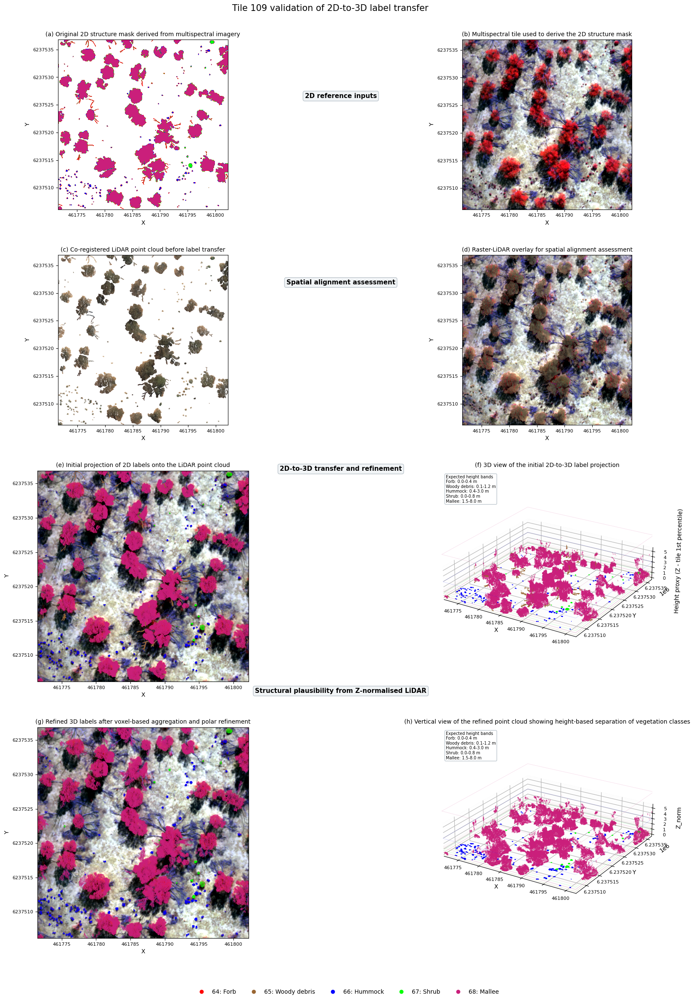

Projected LAS does not contain Z_norm; using a local height proxy computed as Z minus the 1st percentile of tile elevation.
Projected validation points: 180,000
Refined validation points: 180,000
Saved gallery figure: /media/laura/8402326D023263F8/calperumResearch/site1_1_DD0001/lidar/clipped/validation/label_transfer_validation_gallery_tile109.png


In [58]:
validation_mask, validation_transform = read_mask(str(mask_path))
validation_mask = np.where(np.isin(validation_mask, VALIDATION_CLASS_CODES), validation_mask, 0)
validation_mask_codes = [0, *VALIDATION_CLASS_CODES]
validation_mask_idx = remap_to_index(validation_mask, validation_mask_codes)
validation_extent = raster_extent_from_transform(validation_mask.shape, validation_transform)


def build_validation_mask_style(class_codes: tuple[int, ...]) -> tuple[ListedColormap, BoundaryNorm]:
    colors = [(0.0, 0.0, 0.0, 0.0)]
    colors.extend([(*OVERLAY_CLASS_COLORS[code], 1.0) for code in class_codes])
    cmap = ListedColormap(colors)
    bounds = np.arange(-0.5, len(colors) + 0.5, 1.0)
    norm = BoundaryNorm(bounds, cmap.N)
    return cmap, norm


validation_cmap, validation_norm = build_validation_mask_style(VALIDATION_CLASS_CODES)

projected_validation = sample_points(
    filter_points_by_class(read_las_points(str(projected_las_path)), VALIDATION_CLASS_CODES),
    max_points=180_000,
    seed=42,
)
refined_validation = sample_points(
    filter_points_by_class(read_las_points(str(refined_las_path)), VALIDATION_CLASS_CODES),
    max_points=180_000,
    seed=42,
)


def validation_colors(class_values: np.ndarray) -> np.ndarray:
    return np.array([OVERLAY_CLASS_COLORS.get(int(code), '#8f8f8f') for code in class_values], dtype=object)


def validation_z(points: dict[str, np.ndarray | None]) -> np.ndarray:
    z_norm = points.get('z_norm')
    if z_norm is not None:
        return np.asarray(z_norm, dtype=np.float32)
    z_values = np.asarray(points['z'], dtype=np.float32)
    baseline = float(np.nanpercentile(z_values, 1))
    return z_values - baseline


def validation_z_label(points: dict[str, np.ndarray | None]) -> str:
    if points.get('z_norm') is not None:
        return 'Z_norm'
    return 'Height proxy (Z - tile 1st percentile)'


def combined_z_limits(*points_sets: dict[str, np.ndarray | None]) -> tuple[float, float]:
    finite_values = []
    for points in points_sets:
        z_values = validation_z(points)
        z_values = z_values[np.isfinite(z_values)]
        if z_values.size:
            finite_values.append(z_values)
    if not finite_values:
        return (0.0, 1.0)
    merged = np.concatenate(finite_values)
    z_min = float(np.min(merged))
    z_max = float(np.max(merged))
    padding = 0.05 * max(z_max - z_min, 1.0)
    return (z_min - padding, z_max + padding)


def sample_display_las(las_path: Path, max_points: int = 200_000, seed: int = 42) -> dict[str, np.ndarray | bool]:
    las = laspy.read(str(las_path))
    x_values = np.asarray(las.x)
    y_values = np.asarray(las.y)
    use_rgb = hasattr(las, 'red') and hasattr(las, 'green') and hasattr(las, 'blue')
    if use_rgb:
        red = np.asarray(las.red, dtype=np.float32)
        green = np.asarray(las.green, dtype=np.float32)
        blue = np.asarray(las.blue, dtype=np.float32)
        colors = np.stack([red, green, blue], axis=-1) / 65535.0
    else:
        z_values = np.asarray(las.z, dtype=np.float32)
        z_lo, z_hi = np.percentile(z_values, [2, 98])
        colors = np.clip((z_values - z_lo) / (z_hi - z_lo + 1e-6), 0, 1)

    if len(x_values) > max_points:
        rng = np.random.default_rng(seed)
        keep = rng.choice(len(x_values), size=max_points, replace=False)
        x_values = x_values[keep]
        y_values = y_values[keep]
        colors = colors[keep]

    return {
        'x': x_values,
        'y': y_values,
        'colors': colors,
        'use_rgb': use_rgb,
    }


def format_planar_panel(ax, extent: tuple[float, float, float, float]) -> None:
    ax.set_xlim(extent[0], extent[1])
    ax.set_ylim(extent[2], extent[3])
    ax.set_aspect('equal')
    ax.tick_params(labelsize=8)
    ax.ticklabel_format(style='plain', axis='both', useOffset=False)


def add_validation_header(fig, left_ax, right_ax, text: str) -> None:
    left_pos = left_ax.get_position()
    right_pos = right_ax.get_position()
    fig.text(
        (left_pos.x0 + right_pos.x1) / 2,
        left_pos.y1 + 0.014,
        text,
        ha='center',
        va='center',
        fontsize=11,
        fontweight='bold',
        bbox={'boxstyle': 'round,pad=0.28', 'facecolor': '#f1f4f6', 'edgecolor': '#b7c1c9', 'alpha': 0.95},
    )


def add_height_reference_guides(ax) -> None:
    x_min, x_max = overlay_extent[0], overlay_extent[1]
    y_min, y_max = overlay_extent[2], overlay_extent[3]
    x_mesh = np.array([[x_min, x_max], [x_min, x_max]], dtype=np.float32)
    y_mesh = np.array([[y_min, y_min], [y_max, y_max]], dtype=np.float32)
    legend_lines = []
    for code in VALIDATION_CLASS_CODES:
        z_min, z_max = HEIGHT_RANGES[code]
        color = OVERLAY_CLASS_COLORS[code]
        for z_level, alpha in ((z_min, 0.08), (z_max, 0.16)):
            z_mesh = np.full_like(x_mesh, z_level, dtype=np.float32)
            ax.plot_wireframe(x_mesh, y_mesh, z_mesh, color=color, linewidth=0.6, alpha=alpha)
        legend_lines.append(f"{OVERLAY_CLASS_LABELS[code]}: {z_min:.1f}-{z_max:.1f} m")
    ax.text2D(
        0.02,
        0.98,
        'Expected height bands\n' + '\n'.join(legend_lines),
        transform=ax.transAxes,
        va='top',
        ha='left',
        fontsize=7,
        bbox={'boxstyle': 'round,pad=0.25', 'facecolor': 'white', 'edgecolor': '#b7c1c9', 'alpha': 0.92},
    )


def plot_las_only_panel(ax, las_display: dict[str, np.ndarray | bool], title: str) -> None:
    colors = np.asarray(las_display['colors'])
    if bool(las_display['use_rgb']):
        ax.scatter(las_display['x'], las_display['y'], s=0.5, c=colors, alpha=0.75, linewidths=0)
    else:
        ax.scatter(las_display['x'], las_display['y'], s=0.5, c=colors, cmap='viridis', alpha=0.75, linewidths=0)
    ax.set_title(title, fontsize=10)
    ax.set_xlabel('X')
    ax.set_ylabel('Y')
    format_planar_panel(ax, overlay_extent)


def plot_raster_las_overlay_panel(ax, las_display: dict[str, np.ndarray | bool], title: str) -> None:
    ax.imshow(rgb_overlay, extent=overlay_extent, origin='upper')
    colors = np.asarray(las_display['colors'])
    if bool(las_display['use_rgb']):
        ax.scatter(las_display['x'], las_display['y'], s=0.45, c=colors, alpha=0.6, linewidths=0)
    else:
        ax.scatter(las_display['x'], las_display['y'], s=0.45, c=colors, cmap='viridis', alpha=0.6, linewidths=0)
    ax.set_title(title, fontsize=10)
    ax.set_xlabel('X')
    ax.set_ylabel('Y')
    format_planar_panel(ax, overlay_extent)


def plot_overlay_panel(ax, points: dict[str, np.ndarray | None], title: str) -> None:
    ax.imshow(rgb_overlay, extent=overlay_extent, origin='upper')
    ax.scatter(
        points['x'],
        points['y'],
        s=0.55,
        c=validation_colors(np.asarray(points['class'])),
        alpha=0.68,
        linewidths=0,
    )
    ax.set_title(title, fontsize=10)
    ax.set_xlabel('X')
    ax.set_ylabel('Y')
    format_planar_panel(ax, overlay_extent)


def plot_3d_panel(
    ax,
    points: dict[str, np.ndarray | None],
    title: str,
    z_limits: tuple[float, float],
) -> None:
    z_values = validation_z(points)
    x_span = max(overlay_extent[1] - overlay_extent[0], 1e-6)
    y_span = max(overlay_extent[3] - overlay_extent[2], 1e-6)
    z_span = max(z_limits[1] - z_limits[0], 1e-6)
    ax.scatter(
        points['x'],
        points['y'],
        z_values,
        s=0.55,
        c=validation_colors(np.asarray(points['class'])),
        alpha=0.72,
        linewidths=0,
        depthshade=False,
    )
    add_height_reference_guides(ax)
    ax.set_title(title, fontsize=10)
    ax.set_xlabel('X')
    ax.set_ylabel('Y')
    ax.set_zlabel(validation_z_label(points))
    ax.set_xlim(overlay_extent[0], overlay_extent[1])
    ax.set_ylim(overlay_extent[2], overlay_extent[3])
    ax.set_zlim(*z_limits)
    ax.view_init(elev=24, azim=-58)
    ax.grid(True, alpha=0.3)
    ax.xaxis.pane.set_alpha(0.05)
    ax.yaxis.pane.set_alpha(0.05)
    ax.zaxis.pane.set_alpha(0.08)
    ax.xaxis.set_major_formatter(ScalarFormatter(useOffset=False))
    ax.yaxis.set_major_formatter(ScalarFormatter(useOffset=False))
    ax.zaxis.set_major_formatter(ScalarFormatter(useOffset=False))
    ax.tick_params(labelsize=8)
    ax.set_box_aspect((x_span, y_span, z_span * 1.18))


projected_las_display = sample_display_las(projected_las_path)
z_limits = combined_z_limits(projected_validation, refined_validation)

fig = plt.figure(figsize=(20, 24))
grid = fig.add_gridspec(
    4,
    4,
    height_ratios=(0.95, 0.95, 1.18, 1.18),
    width_ratios=(1.0, 1.0, 1.0, 1.0),
    hspace=0.24,
    wspace=0.12,
)

axes = {
    'a': fig.add_subplot(grid[0, 0:2]),
    'b': fig.add_subplot(grid[0, 2:4]),
    'c': fig.add_subplot(grid[1, 0:2]),
    'd': fig.add_subplot(grid[1, 2:4]),
    'e': fig.add_subplot(grid[2, 0:2]),
    'f': fig.add_subplot(grid[2, 2:4], projection='3d'),
    'g': fig.add_subplot(grid[3, 0:2]),
    'h': fig.add_subplot(grid[3, 2:4], projection='3d'),
}

axes['a'].imshow(
    validation_mask_idx,
    cmap=validation_cmap,
    norm=validation_norm,
    extent=validation_extent,
    origin='upper',
)
axes['a'].set_title('(a) Original 2D structure mask derived from multispectral imagery', fontsize=10)
axes['a'].set_xlabel('X')
axes['a'].set_ylabel('Y')
format_planar_panel(axes['a'], validation_extent)

axes['b'].imshow(rgb_overlay, extent=overlay_extent, origin='upper')
axes['b'].set_title('(b) Multispectral tile used to derive the 2D structure mask', fontsize=10)
axes['b'].set_xlabel('X')
axes['b'].set_ylabel('Y')
format_planar_panel(axes['b'], overlay_extent)

plot_las_only_panel(axes['c'], projected_las_display, '(c) Co-registered LiDAR point cloud before label transfer')
plot_raster_las_overlay_panel(axes['d'], projected_las_display, '(d) Raster-LiDAR overlay for spatial alignment assessment')
plot_overlay_panel(axes['e'], projected_validation, '(e) Initial projection of 2D labels onto the LiDAR point cloud')
plot_3d_panel(axes['f'], projected_validation, '(f) 3D view of the initial 2D-to-3D label projection', z_limits)
plot_overlay_panel(axes['g'], refined_validation, '(g) Refined 3D labels after voxel-based aggregation and polar refinement')
plot_3d_panel(axes['h'], refined_validation, '(h) Vertical view of the refined point cloud showing height-based separation of vegetation classes', z_limits)

add_validation_header(fig, axes['a'], axes['b'], '2D reference inputs')
add_validation_header(fig, axes['c'], axes['d'], 'Spatial alignment assessment')
add_validation_header(fig, axes['e'], axes['f'], '2D-to-3D transfer and refinement')
add_validation_header(fig, axes['g'], axes['h'], 'Structural plausibility from Z-normalised LiDAR')

legend_handles = [
    plt.Line2D(
        [0],
        [0],
        marker='o',
        color='w',
        markerfacecolor=OVERLAY_CLASS_COLORS[code],
        markersize=8,
        linestyle='None',
        label=f'{code}: {OVERLAY_CLASS_LABELS[code]}',
    )
    for code in VALIDATION_CLASS_CODES
]
fig.legend(handles=legend_handles, loc='lower center', ncol=5, frameon=False)
fig.suptitle(f'Tile {tile_id} validation of 2D-to-3D label transfer', fontsize=15, y=0.985)
fig.subplots_adjust(left=0.05, right=0.985, top=0.95, bottom=0.06)
gallery_output_path.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(gallery_output_path, dpi=300, bbox_inches='tight')
plt.show()

if projected_validation.get('z_norm') is None:
    print('Projected LAS does not contain Z_norm; using a local height proxy computed as Z minus the 1st percentile of tile elevation.')

print(f'Projected validation points: {len(projected_validation["x"]):,}')
print(f'Refined validation points: {len(refined_validation["x"]):,}')
print(f'Saved gallery figure: {gallery_output_path}')

## Results Validation

The validation gallery is organised to mirror the methodological workflow. The first row focuses on spatial alignment assessment by comparing the original 2D mask, the multispectral reference image, the co-registered LAS point cloud, and their direct overlay.

The lower panels then show the initial 2D-to-3D label projection, the refined voxel and polar labels, and paired 3D views with expected height guides derived from Z-normalised LiDAR. This arrangement makes it easier to assess both geometric consistency and structural plausibility within the same figure.

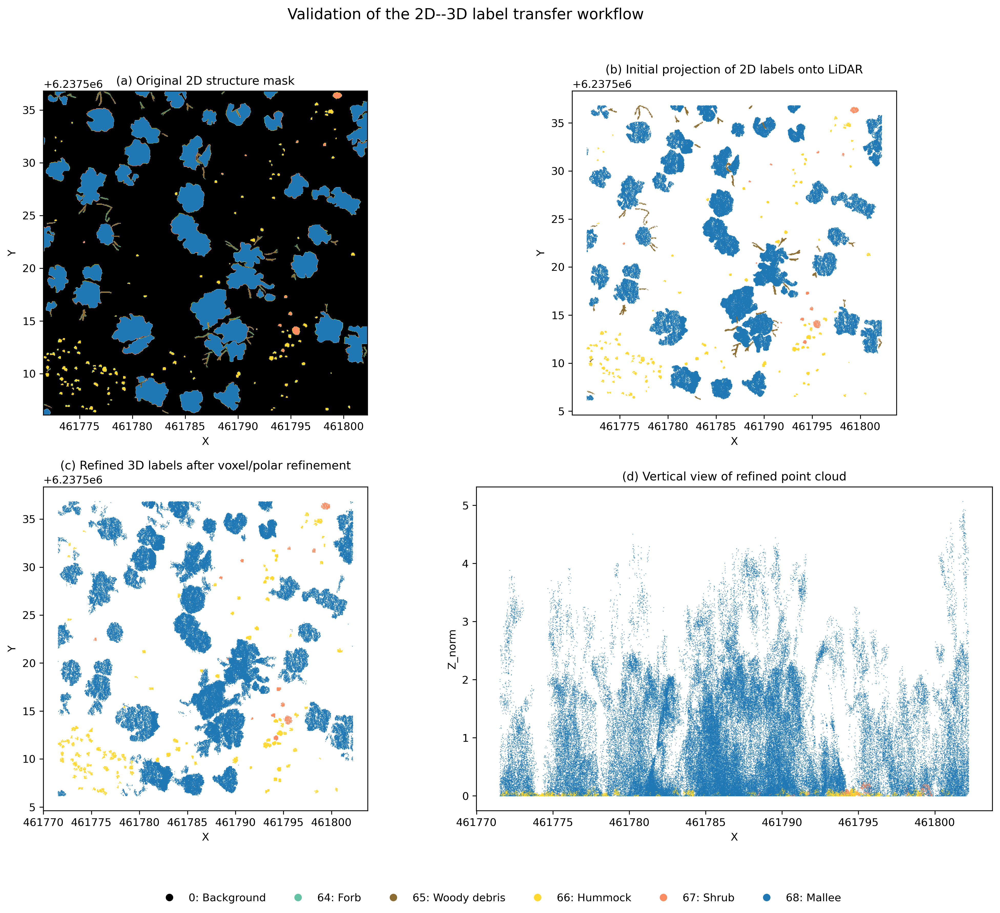

Saved results figure: /media/laura/8402326D023263F8/calperumResearch/site1_1_DD0001/lidar/clipped/validation/label_transfer_validation_results_tile109.png


In [6]:
make_label_transfer_validation_figure(
    mask_path=str(mask_path),
    projected_las_path=str(projected_las_path),
    refined_las_path=str(refined_las_path),
    output_path=str(results_output_path),
    class_codes=VALIDATION_CLASS_CODES,
    max_points=150_000,
    point_size=0.5,
    show_background_mask=False,
    sample_seed=42,
)

display(Image(filename=str(results_output_path)))
print(f'Saved results figure: {results_output_path}')

In [7]:
def aggregate_majority_by_mask_cell(
    points: dict[str, np.ndarray | None],
    transform,
    shape: tuple[int, int],
) -> tuple[np.ndarray, np.ndarray]:
    x_values = np.asarray(points['x'])
    y_values = np.asarray(points['y'])
    class_values = np.asarray(points['class'])
    keep = np.isin(class_values, VALIDATION_CLASS_CODES)
    x_values = x_values[keep]
    y_values = y_values[keep]
    class_values = class_values[keep]

    rows, cols = rasterio.transform.rowcol(transform, x_values, y_values)
    rows = np.asarray(rows)
    cols = np.asarray(cols)
    valid = (rows >= 0) & (rows < shape[0]) & (cols >= 0) & (cols < shape[1])
    rows = rows[valid]
    cols = cols[valid]
    class_values = class_values[valid]

    if len(class_values) == 0:
        return np.array([], dtype=np.int64), np.array([], dtype=np.int16)

    cell_ids = rows.astype(np.int64) * shape[1] + cols.astype(np.int64)
    order = np.argsort(cell_ids)
    cell_ids = cell_ids[order]
    class_values = class_values[order]

    unique_cells = []
    majority_classes = []
    start = 0
    for stop in range(1, len(cell_ids) + 1):
        if stop < len(cell_ids) and cell_ids[stop] == cell_ids[start]:
            continue
        unique_cells.append(cell_ids[start])
        values = class_values[start:stop]
        codes, counts = np.unique(values, return_counts=True)
        majority_classes.append(int(codes[np.argmax(counts)]))
        start = stop

    return np.asarray(unique_cells, dtype=np.int64), np.asarray(majority_classes, dtype=np.int16)


def compute_label_agreement_table() -> pd.DataFrame:
    projected_cells, projected_classes = aggregate_majority_by_mask_cell(
        projected_validation,
        validation_transform,
        validation_mask.shape,
    )
    refined_cells, refined_classes = aggregate_majority_by_mask_cell(
        refined_validation,
        validation_transform,
        validation_mask.shape,
    )

    common_cells = np.intersect1d(projected_cells, refined_cells)
    if len(common_cells) == 0:
        return pd.DataFrame([
            {
                'Tile': tile_id,
                'Site': site_root.name,
                'OA (%)': np.nan,
                'IoU Forb': np.nan,
                'IoU Woody debris': np.nan,
                'IoU Hummock': np.nan,
                'IoU Shrub': np.nan,
                'IoU Mallee': np.nan,
            }
        ])

    projected_lookup = dict(zip(projected_cells.tolist(), projected_classes.tolist()))
    refined_lookup = dict(zip(refined_cells.tolist(), refined_classes.tolist()))
    projected_common = np.asarray([projected_lookup[int(cell)] for cell in common_cells], dtype=np.int16)
    refined_common = np.asarray([refined_lookup[int(cell)] for cell in common_cells], dtype=np.int16)

    row = {
        'Tile': tile_id,
        'Site': site_root.name,
        'OA (%)': float(np.mean(projected_common == refined_common) * 100.0),
    }

    for code in VALIDATION_CLASS_CODES:
        true_mask = projected_common == code
        pred_mask = refined_common == code
        tp = int(np.sum(true_mask & pred_mask))
        fp = int(np.sum(~true_mask & pred_mask))
        fn = int(np.sum(true_mask & ~pred_mask))
        denom = tp + fp + fn
        key = f'IoU {OVERLAY_CLASS_LABELS[code]}'
        row[key] = float(tp / denom) if denom else np.nan

    return pd.DataFrame([row])


table5_current_tile = compute_label_agreement_table()
table5_template = pd.DataFrame(
    [
        {'Tile': 'T01', 'Site': 'Medium'},
        {'Tile': 'T02', 'Site': 'Medium'},
        {'Tile': 'T03', 'Site': 'Low'},
    ]
)
for column in [
    'OA (%)',
    'IoU Forb',
    'IoU Woody debris',
    'IoU Hummock',
    'IoU Shrub',
    'IoU Mallee',
]:
    table5_template[column] = np.nan

print('Table 5: Current tile agreement summary computed on common occupied mask cells')
display(table5_current_tile.round(3))

print('Table 5 manuscript template for representative tiles')
display(table5_template)

Table 5: Current tile agreement summary computed on common occupied mask cells


,Tile,Site,OA (%),IoU Forb,IoU Woody debris,IoU Hummock,IoU Shrub,IoU Mallee
0,109,site1_1_DD0001,99.015,NaN,0.0,0.999,1.0,0.99


Table 5 manuscript template for representative tiles


,Tile,Site,OA (%),IoU Forb,IoU Woody debris,IoU Hummock,IoU Shrub,IoU Mallee
0,T01,Medium,NaN,NaN,NaN,NaN,NaN,NaN
1,T02,Medium,NaN,NaN,NaN,NaN,NaN,NaN
2,T03,Low,NaN,NaN,NaN,NaN,NaN,NaN


Table 6: Height-based plausibility of refined 3D labels using Z_norm


,Class,Median Znorm (m),IQR (m),Out-of-range points (%)
0,Forb,NaN,NaN,NaN
1,Woody debris,NaN,NaN,NaN
2,Hummock,0.020,0.043,99.923
3,Shrub,0.044,0.074,0.240
4,Mallee,0.650,1.296,75.127


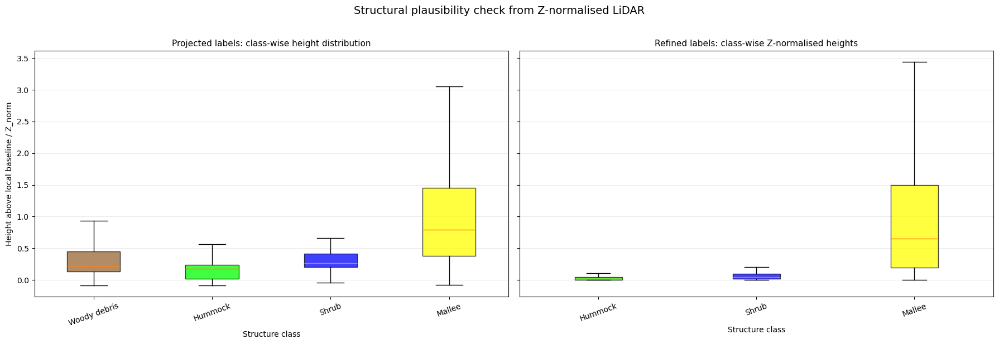

Hummock (66): projected median=0.18 m, refined median=0.02 m
Shrub (67): projected median=0.26 m, refined median=0.04 m
Mallee (68): projected median=0.79 m, refined median=0.65 m
Height ranges used for Table 6 and refinement priors:
  Forb (64): 0.00 to 0.40 m
  Woody debris (65): 0.05 to 1.20 m
  Hummock (66): 0.40 to 3.00 m
  Shrub (67): 0.00 to 0.80 m
  Mallee (68): 1.50 to 8.00 m
Saved height QC figure: /media/laura/8402326D023263F8/calperumResearch/site1_1_DD0001/lidar/clipped/validation/label_transfer_validation_height_qc_tile109.png


In [8]:

def class_height_values(points: dict[str, np.ndarray | None]) -> dict[int, np.ndarray]:
    z_values = validation_z(points).astype(np.float32)
    class_values = np.asarray(points['class'])
    return {
        code: z_values[class_values == code]
        for code in VALIDATION_CLASS_CODES
    }


def build_height_plausibility_table(dataset: dict[int, np.ndarray]) -> pd.DataFrame:
    rows = []
    for code in VALIDATION_CLASS_CODES:
        values = np.asarray(dataset[code], dtype=np.float32)
        zmin, zmax = HEIGHT_RANGES[code]
        if len(values) == 0:
            rows.append({
                'Class': OVERLAY_CLASS_LABELS[code],
                'Median Znorm (m)': np.nan,
                'IQR (m)': np.nan,
                'Out-of-range points (%)': np.nan,
            })
            continue
        q1, q3 = np.percentile(values, [25, 75])
        out_of_range = ((values < zmin) | (values > zmax)).mean() * 100.0
        rows.append({
            'Class': OVERLAY_CLASS_LABELS[code],
            'Median Znorm (m)': float(np.median(values)),
            'IQR (m)': float(q3 - q1),
            'Out-of-range points (%)': float(out_of_range),
        })
    return pd.DataFrame(rows)


projected_height_data = class_height_values(projected_validation)
refined_height_data = class_height_values(refined_validation)
table6_refined = build_height_plausibility_table(refined_height_data)

print('Table 6: Height-based plausibility of refined 3D labels using Z_norm')
display(table6_refined.round(3))

fig, axes = plt.subplots(1, 2, figsize=(18, 6), sharey=True)

for ax, dataset, title in [
    (axes[0], projected_height_data, 'Projected labels: class-wise height distribution'),
    (axes[1], refined_height_data, 'Refined labels: class-wise Z-normalised heights'),
]:
    present_codes = [code for code in VALIDATION_CLASS_CODES if len(dataset[code]) > 0]
    if not present_codes:
        ax.text(0.5, 0.5, 'No points available for the selected classes', ha='center', va='center', transform=ax.transAxes)
        ax.set_axis_off()
        continue
    box = ax.boxplot(
        [dataset[code] for code in present_codes],
        patch_artist=True,
        showfliers=False,
        tick_labels=[OVERLAY_CLASS_LABELS[code] for code in present_codes],
    )
    for patch, code in zip(box['boxes'], present_codes):
        patch.set_facecolor(OVERLAY_CLASS_COLORS[code])
        patch.set_alpha(0.75)
    ax.set_title(title, fontsize=11)
    ax.set_xlabel('Structure class')
    ax.tick_params(axis='x', rotation=20)
    ax.grid(True, axis='y', alpha=0.25)

axes[0].set_ylabel('Height above local baseline / Z_norm')
fig.suptitle('Structural plausibility check from Z-normalised LiDAR', fontsize=14, y=1.02)
fig.tight_layout()
height_output_path.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(height_output_path, dpi=300, bbox_inches='tight')
plt.show()

for code in VALIDATION_CLASS_CODES:
    projected_values = projected_height_data[code]
    refined_values = refined_height_data[code]
    if len(projected_values) == 0 or len(refined_values) == 0:
        continue
    print(
        f'{OVERLAY_CLASS_LABELS[code]} ({code}): projected median={np.median(projected_values):.2f} m, refined median={np.median(refined_values):.2f} m'
    )

print('Height ranges used for Table 6 and refinement priors:')
for code, (zmin, zmax) in HEIGHT_RANGES.items():
    print(f'  {OVERLAY_CLASS_LABELS[code]} ({code}): {zmin:.2f} to {zmax:.2f} m')

print(f'Saved height QC figure: {height_output_path}')